# Practice PS07: Outlier analysis

Author: <font color="#2680EB">Bo-Yu Chen</font>

E-mail: <font color="#2680EB">8011chen@gmail.com</font>

AI used: <font color="#2680EB">Chatgpt, I don't know which model, used for explain the problem description in this notebook.</font>

Date: <font color="#2680EB">10/11/2026</font>

In [1]:
# LEAVE THIS CELL AS-IS
import csv
import io
import random

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.decomposition import PCA

# 0. Dataset

In [2]:
# LEAVE AS-IS

# Load both datasets
dft = pd.read_csv('annthyroid.csv', sep=',')
dfc = pd.read_csv('cardio.csv', sep=',')
dfb = pd.read_csv('breast_cancer.csv', sep=',')

# 1. Exploratory analysis

In [3]:
# LEAVE AS-IS

def print_normal_abnormal(df, dataset_name):
    print(f"The {dataset_name} dataset contains {len(df)} patients")
    n_normal = len(df[df['result'] == 'normal'])
    n_abnormal = len(df[df['result'] == 'abnormal'])
    print(" Normal   : %d (%.2f%%)" % ( n_normal, 100*n_normal / (n_normal + n_abnormal)))
    print(" Abnormal : %d (%.2f%%)" % ( n_abnormal, 100*n_abnormal / (n_normal + n_abnormal)))
    print()
    
print_normal_abnormal(dft, "Thyroid")
print_normal_abnormal(dfc, "Cardiotocography")
print_normal_abnormal(dfb, "Breast Cancer")

The Thyroid dataset contains 7200 patients
 Normal   : 6666 (92.58%)
 Abnormal : 534 (7.42%)

The Cardiotocography dataset contains 1831 patients
 Normal   : 1655 (90.39%)
 Abnormal : 176 (9.61%)

The Breast Cancer dataset contains 699 patients
 Normal   : 458 (65.52%)
 Abnormal : 241 (34.48%)



## 1.1. Visual inspection for class separation <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement a function to display scatter plots for every pair of features.**</font>

In [4]:

def print_scatter_matrix(dataset, dataset_name, color_normal, color_abnormal):
    print(f"Scatter matrix for the {dataset_name} dataset.")

    # YOUR ANSWER HERE
    color_code = {'abnormal': color_abnormal, 'normal': color_normal}

    sns.pairplot(dataset, hue='result', palette=color_code)

Scatter matrix for the Thyroid dataset.
Scatter matrix for the Breast cancer dataset.


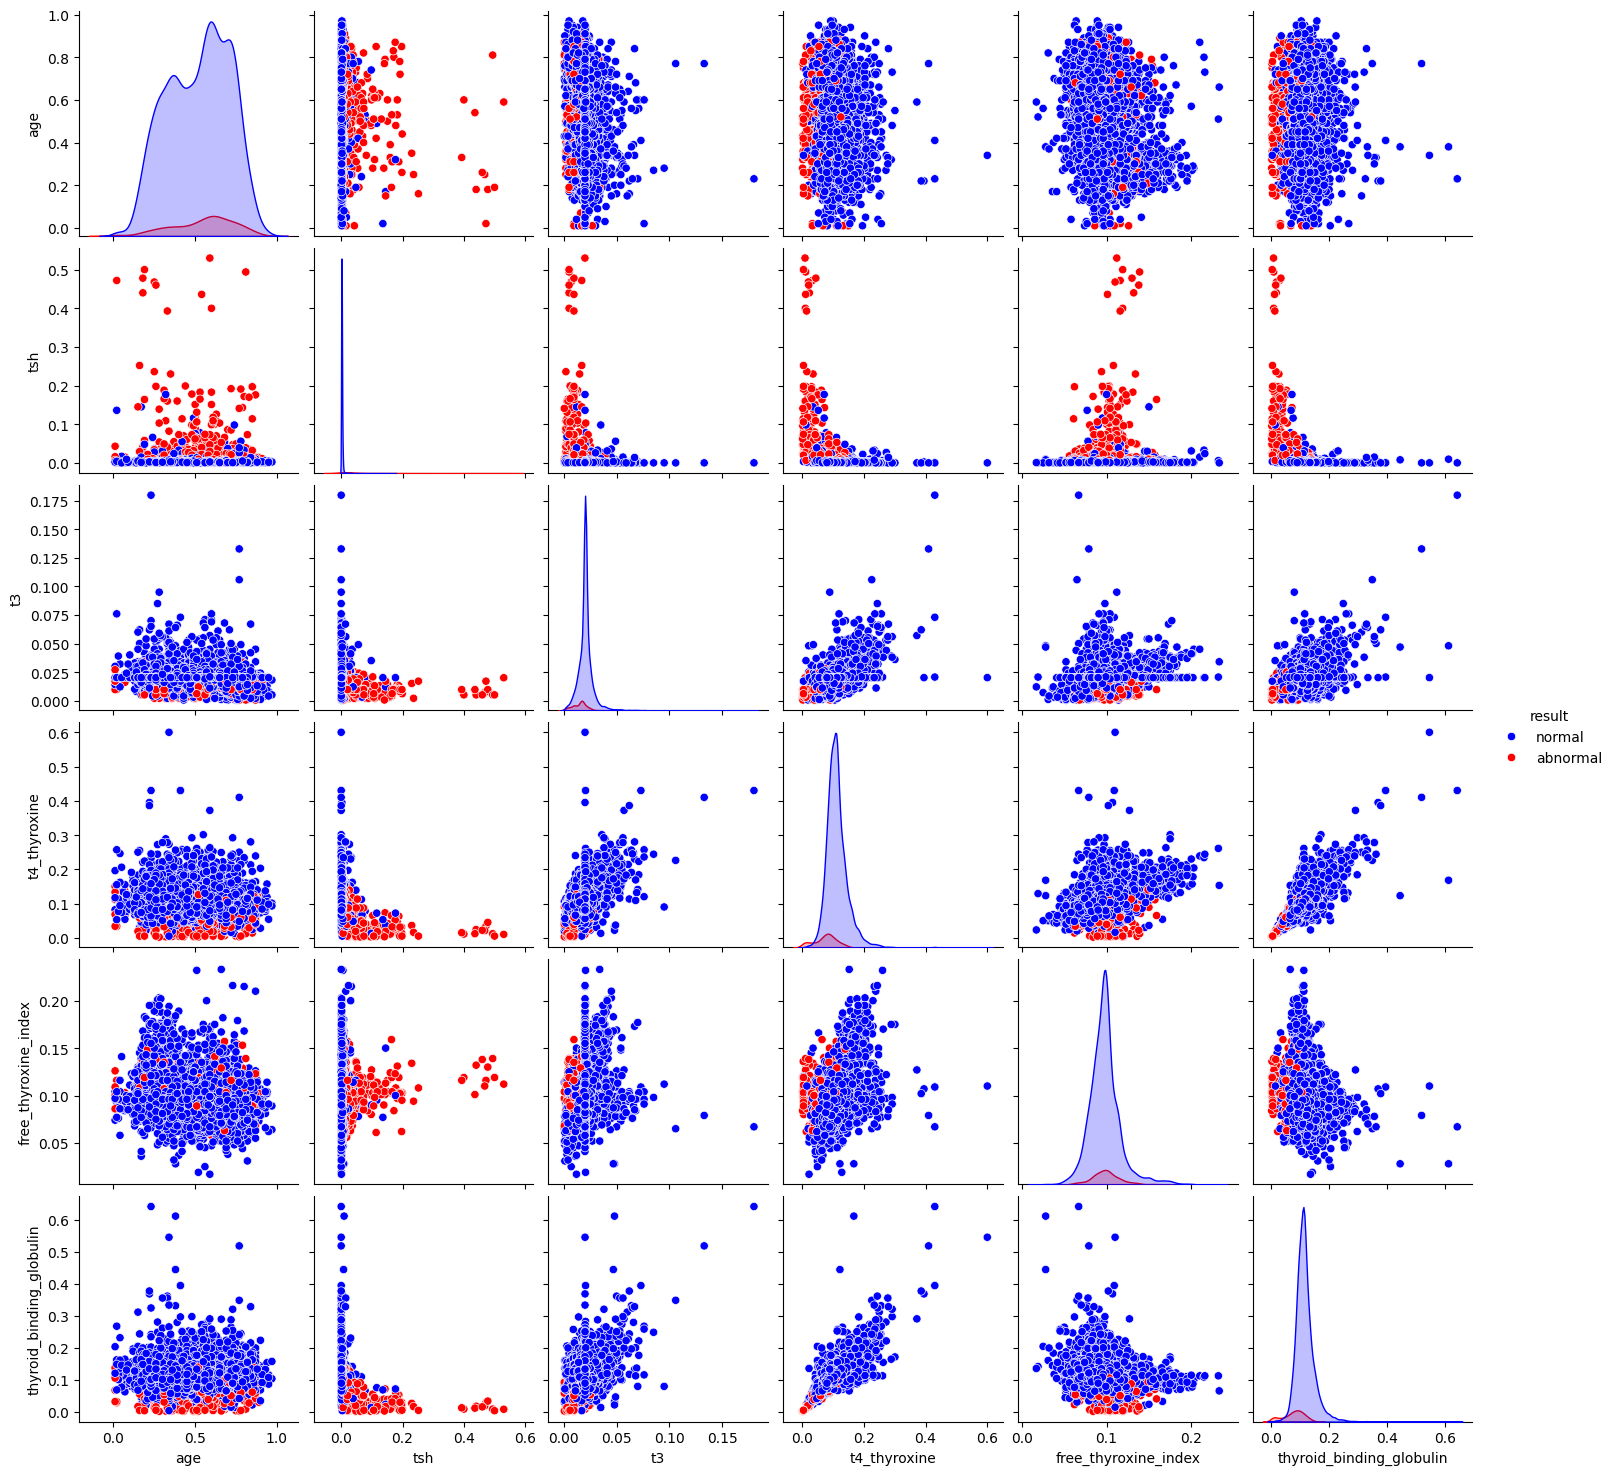

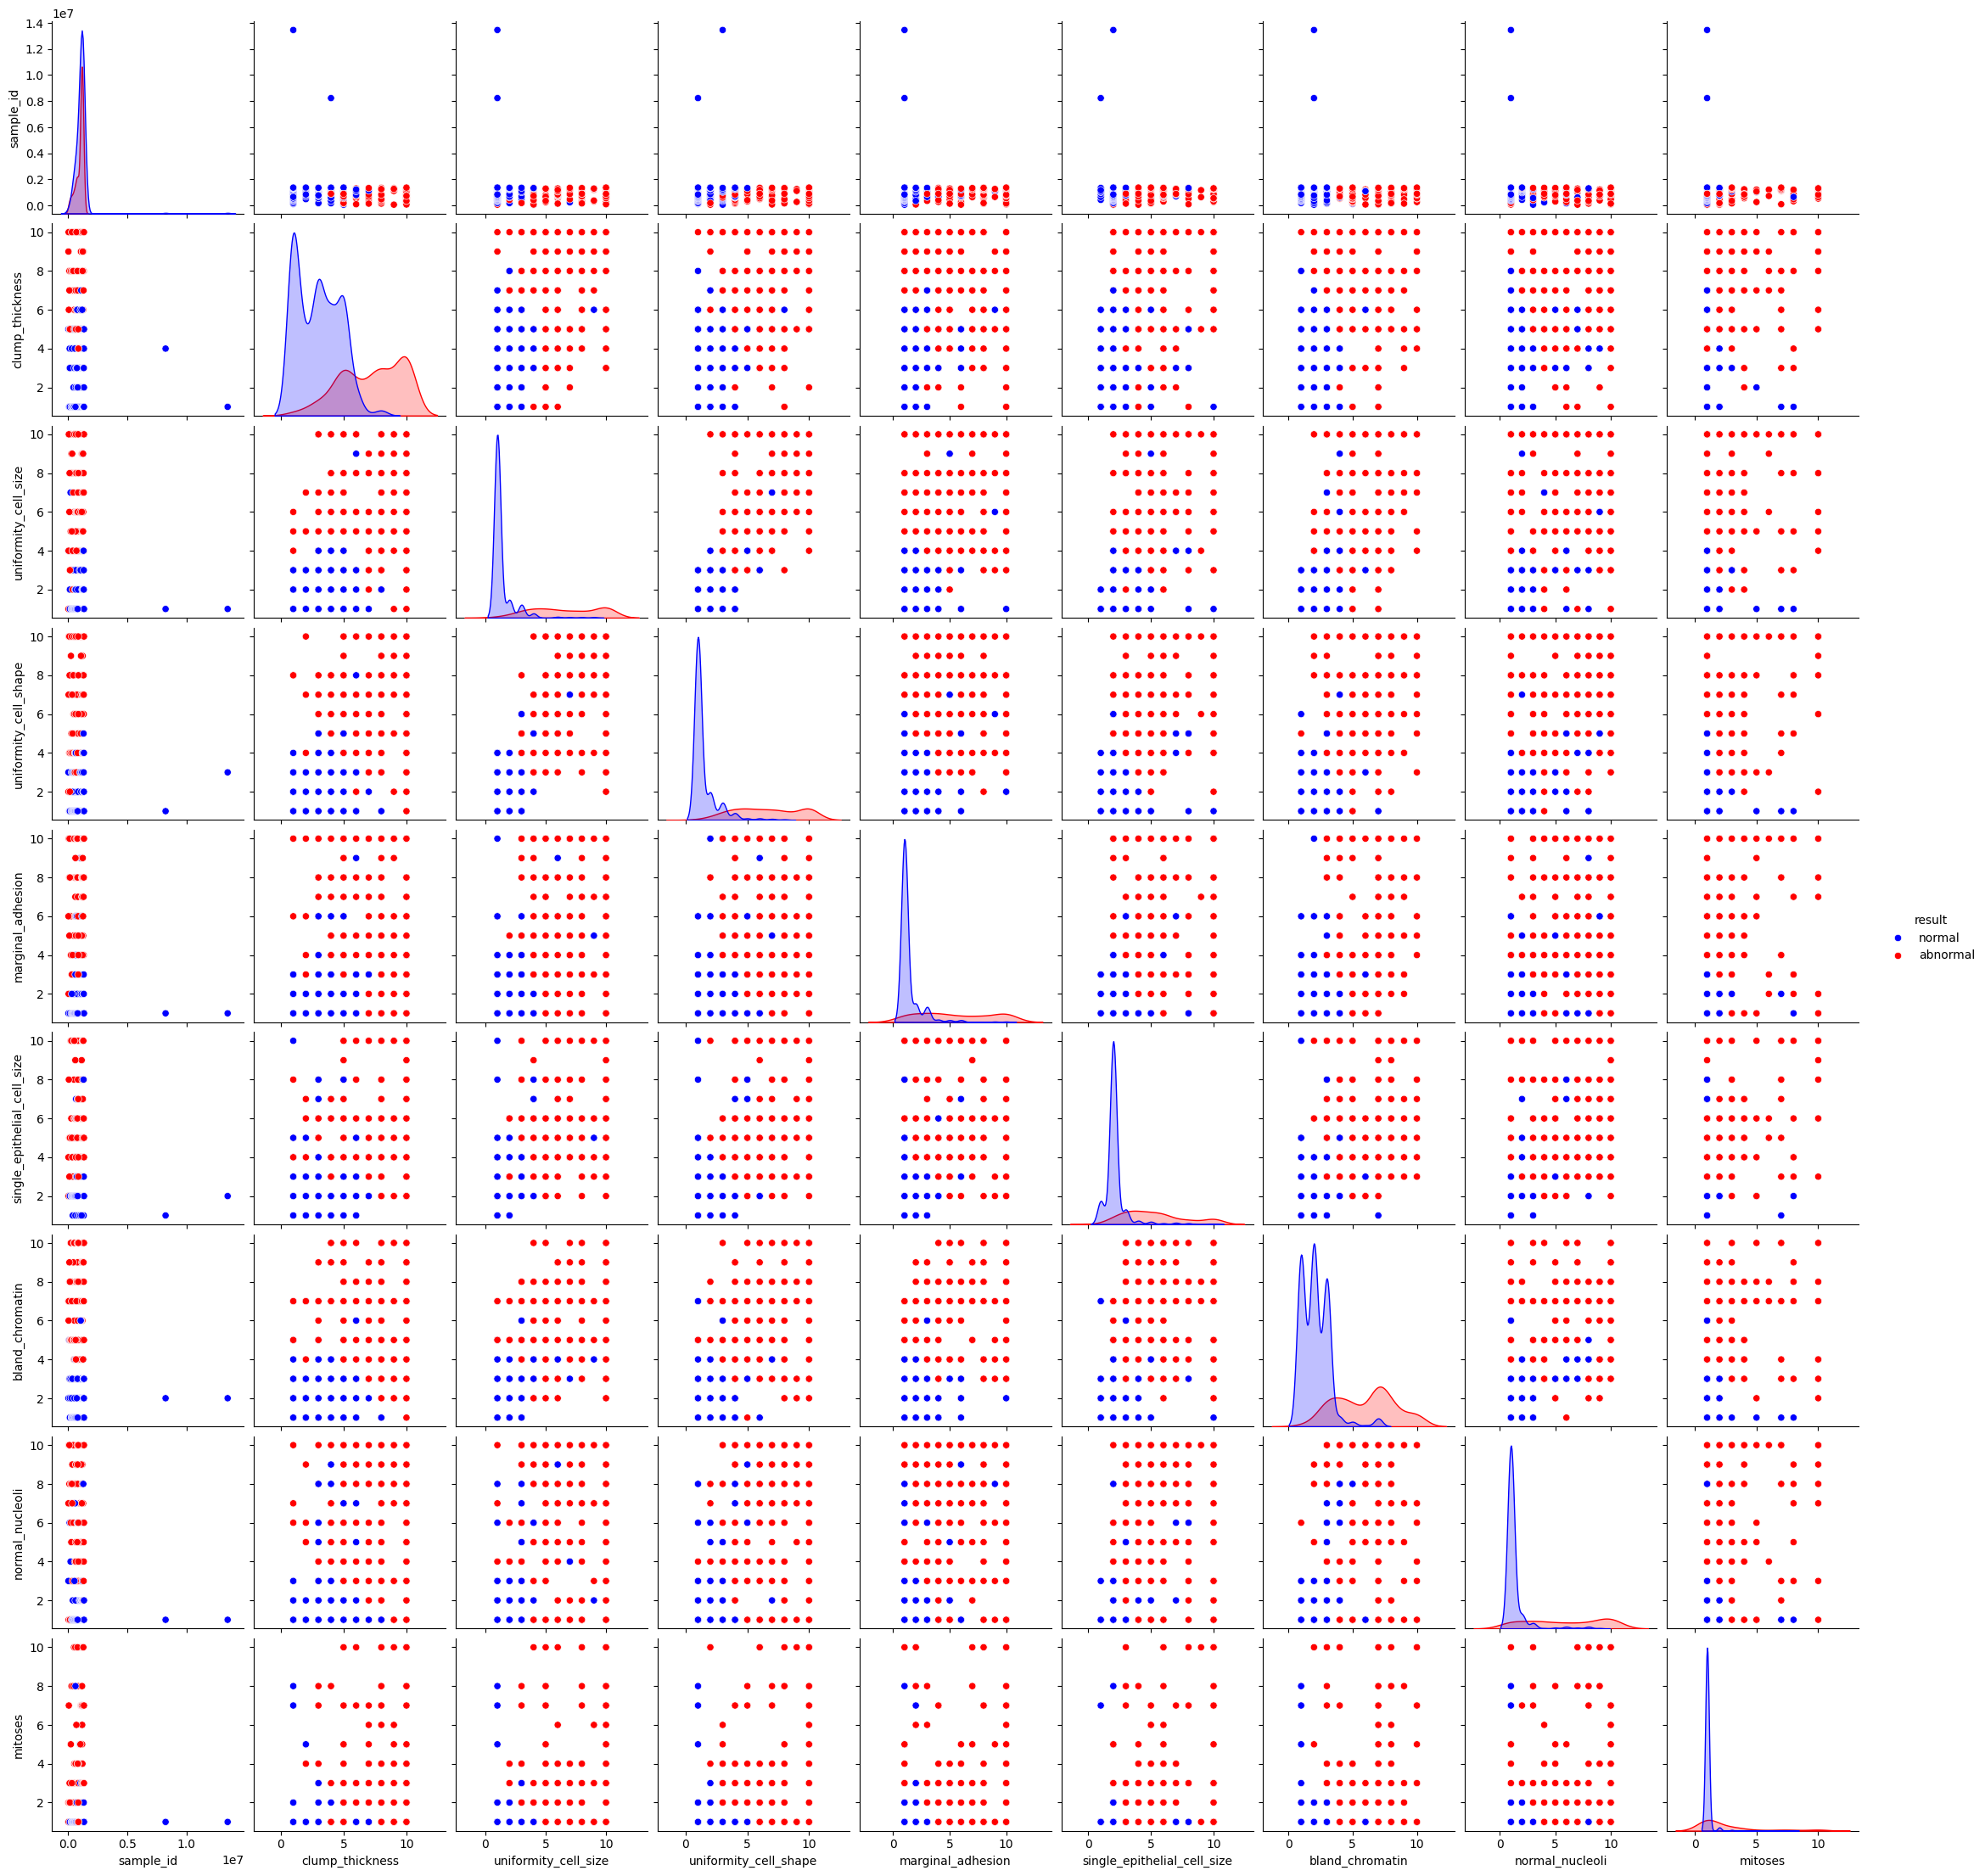

In [5]:
# LEAVE AS-IS

print_scatter_matrix(dft, 'Thyroid', 'blue', 'red')
print_scatter_matrix(dfb, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Examine the scatter plots of combinations of two features.** Answer these questions.</font>

**Answer:**

What do the plots in the diagonal represent?

* In the diagonal plots, they have only one feature, and thus the chart shows the quantity distribution of that feature for two classes.

In the case of the *Thyroid* dataset, is there any single feature that provides good separation between classes, which one (if any)? Are there pairs of features that can do this to some extent? Can you provide an example of such pair of features? In each case (single feature and pair of features), is there complete separability, or some overlap?

* single feature: tsh values for abnormal classes spread averagely, while normal ones center to one small part. While this isn't effective enough, but it can still provide some useful information. The two classes still have overlap.
pairs of feature: tsh and thyroid_binding_globulin. Abnormal ones got a lower thyroid_binding_globulin and more widespread tsh. While normal ones has lower tsh and widespread thyroid_binding_globulin. But two classes still have overlap.


And in the case of the *Breast cancer* dataset?

* single feature: For single feature, I think uniformity_cell_size give the most information. Normal ones has a smaller cell size and abnormal ones has a larger cell size and more different cell size. While two classes still overlap.

feature pair: uniformity_cell_size and uniformity_cell_shape. The normal ones has lower uniformity_cell_size and uniformity_cell_shape, while the abnormal ones has higher uniformity_cell_size and uniformity_cell_shape. The dots likely overlapped but I could not see them in the plot. 

In the *Breast cancer* dataset, many scatterplots look like a grid/lattice, why do you think that happens?

* Instead of continuous value, the data is collected in multiple levels of value. So the values will grouped together like grid.

## 1.2. Visual inspection for outliers  <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement a function that uses PCA to project into two dimensions.** The function should project all features except the last one, which contains the result (normal or abnormal).</font>

In [6]:
def project_2D(df):

    # Extract features, which appear in all columns except the last one
    features = df.iloc[:, :-1]
    
    # Extract the last column, which contains the label
    result = df.iloc[:, -1]
    
    # Replace '?' values (present in one of the datasets) with NULL
    features = features.replace('?', np.nan)
    result = result.replace('?', np.nan)

    # Remove rows with NaN values in the features or the result
    valid_rows = features.notnull().all(axis=1) & result.notnull()
    features = features[valid_rows]
    result = result[valid_rows]
    
    # Apply PCA to project to 2 dimensions
    # Create output dataframe with projected dimensions named X and Y and the result

    # YOUR CODE HERE
    pca = PCA(n_components=2)
    transform = pca.fit_transform(features) 
    output = np.hstack((transform, np.atleast_2d(result).T))
    output = pd.DataFrame(output, columns=['X', 'Y', 'result'])
    
    return output

<font size="+1" color="#2680EB">**Plot the projected datasets.** Reuse the color mapping you defined above.</font>

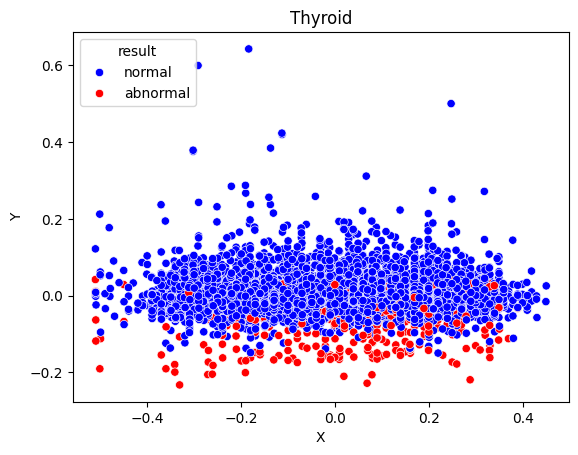

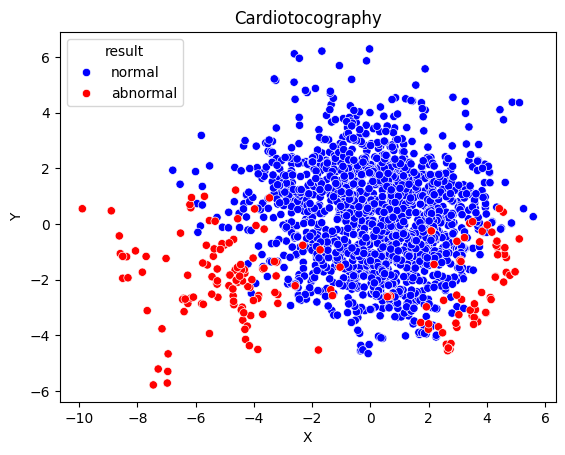

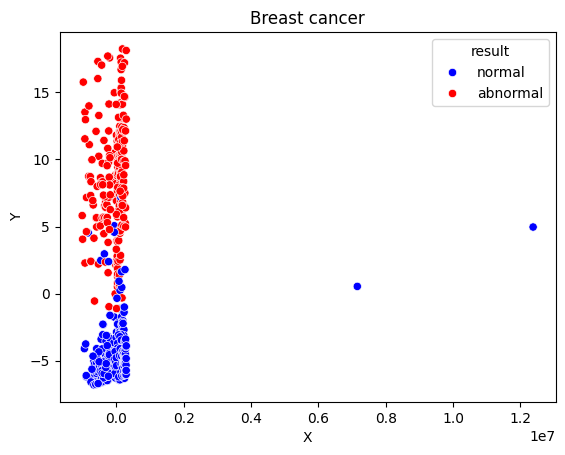

In [7]:
def plot_projected_dataset(dataset, dataset_name, color_normal, color_abnormal):
    df_projected = project_2D(dataset)

    # Create a color palette
    color_code = {'normal': color_normal, 'abnormal': color_abnormal}

    # Plot a scatter plot of df_projected with X on the x-axis and Y on the y-axis
    # Color points by the result column using seaborn
    # YOUR CODE HERE
    sns.scatterplot(
        x="X", y="Y", 
        data=df_projected,
        palette=color_code,
        hue="result"
    ).set(title=dataset_name)
        
    plt.show()

plot_projected_dataset(dft, 'Thyroid', 'blue', 'red')
plot_projected_dataset(dfc, 'Cardiotocography', 'blue', 'red')
plot_projected_dataset(dfb, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Examine the scatter plots of the projected datasets.** Answer these questions.</font>

**Answer:**

In the case of the *Thyroid* dataset, would you say that the abnormal points are *outliers*? Are they extreme values? Briefly justify your answer.

* No, I won't say the abnormal points of Thyroid dataset as outliers, because they are in the main cloud of points. Only a few of the abnormal points with very low Y value is extreme value, where they are in the place with lower density.

And in the case of the *Cardiotocography* dataset?

* No, I won't say the abnormal points of Cardiotocography dataset as outliers, because they are in the main cloud of points. I would say some part of the abnormal points in lower left and lower right as extreme value, where they are in the place with lower density.

And in the case of the *Breast cancer* dataset?

* No, I won't say the abnormal points of Breast cancer dataset as outliers, because they are in the main cloud of points. I also wouldn't say abnormal points as extreme value, because they still have some density even in the higher part.

<font size="+1" color="#2680EB">**Repeat the analysis dropping the "sample_id" feature.**</font>

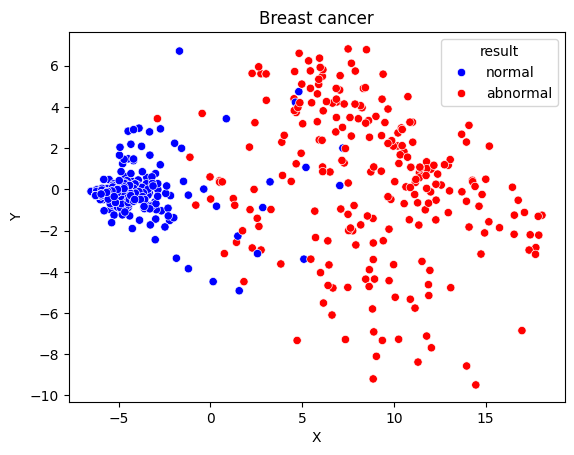

In [8]:
# YOUR ANSWER HERE
dfb_noid = dfb.drop('sample_id', axis=1)
plot_projected_dataset(dfb_noid, 'Breast cancer', 'blue', 'red')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What happened when you removed the sample_id feature from the breast cancer dataset?

* We don't take sample id into account anymore. The two outliers of normal values don't appear anymore, and the 2d plot displays more helpful information. Because sample id could contain very large value, affecting the PCA. The normal points are now tightly together on the left, while the abnormal points are more losely on the right.

Are the abnormal data points outliers? Are they extreme values?

* Yes, the abnormal points are no longer in the same cloud as normal points, so they are outlieres. And they spread more losely, so they are extreme values.

# 2. Create isolation tree

## 2.1. Random dimension and random split  <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement pick_random_dimension.**</font>

In [9]:
def pick_random_dimension(df, columns_to_ignore):
    # YOUR ANSWER HERE
    #AI (edited) explained what to do
    available_columns = [col for col in df.columns if col not in columns_to_ignore]
    return random.choice(available_columns)

In [10]:
# LEAVE AS-IS

print("Random dimensions for the 'thyroid' dataset")
print(pick_random_dimension(dft, ["result"]))
print(pick_random_dimension(dft, ["result"]))
print()

print("Random dimensions for the 'cardio' dataset")
print(pick_random_dimension(dfc, ["result"]))
print(pick_random_dimension(dfc, ["result"]))
print()

print("Random dimensions for the 'breast cancer' dataset")
print(pick_random_dimension(dfb, ["result", "sample_id"]))
print(pick_random_dimension(dfb, ["result", "sample_id"]))
print()

Random dimensions for the 'thyroid' dataset
free_thyroxine_index
free_thyroxine_index

Random dimensions for the 'cardio' dataset
max
MSTV

Random dimensions for the 'breast cancer' dataset
uniformity_cell_size
uniformity_cell_size




<font size="+1" color="#2680EB">**Implement pick_random_split.** It should return a random split point chosen uniformly at random between the minimum and the maximum value along a dimension.</font>

In [11]:
def pick_random_split(df, dimension):
    # YOUR ANSWER HERE
    lower_bound = np.min(df[dimension])
    upper_bound = np.max(df[dimension])
    split_point = random.random()
    split_point = lower_bound + (upper_bound - lower_bound) * split_point
    return split_point

In [12]:
# LEAVE AS-IS

print("Random splits according to 't3' in the 'thyroid' dataset")
print(pick_random_split(dft, "t3"))
print(pick_random_split(dft, "t3"))
print()

print("Random splits according to 'AC' in the 'cardio' dataset")
print(pick_random_split(dfc, "AC"))
print(pick_random_split(dfc, "AC"))
print()

print("Random splits according to 'mitoses' in the 'breast cancer' dataset")
print(pick_random_split(dfb, "mitoses"))
print(pick_random_split(dfb, "mitoses"))
print()

Random splits according to 't3' in the 'thyroid' dataset
0.11401233706103435
0.12065772110626424

Random splits according to 'AC' in the 'cardio' dataset
3.7714607183147506
-0.3497389479129247

Random splits according to 'mitoses' in the 'breast cancer' dataset
6.0596360279045856
3.6370704254681288



## 2.2. Implement splitting a dataset into two parts <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement split_dataset.**</font>

In [13]:
def split_dataset(df, dimension, split):
    # YOUR ANSWER HERE
    df1 = df[df[dimension]<=split]
    df2 = df[df[dimension]>split]
    assert len(df1) + len(df2) == len(df), "The split did not preserve the number of rows."
    return (df1, df2)

<font size="+1" color="#2680EB">**Test split_dataset.** Select a dataset, a dimension, and a cut-off, and split the dataset, then print the two pieces and check that the sum of the sizes of the two pieces is the size of the original data.</font>

In [14]:
# (left, right) = split_dataset( ... )

# YOUR ANSWER HERE
(left, right) = split_dataset(dft, 't3', 0.02)

display(left.head(3))
display(right.head(3))

print(f"Sizes: left={len(left)}, right={len(right)}, sum={len(left)+len(right)} (should be {len(dft)})")

,age,tsh,t3,t4_thyroxine,free_thyroxine_index,thyroid_binding_globulin,result
0,0.73,0.00060,0.015,0.120,0.082,0.146,normal
3,0.64,0.00090,0.017,0.077,0.090,0.085,normal
5,0.69,0.00025,0.016,0.086,0.070,0.123,normal


,age,tsh,t3,t4_thyroxine,free_thyroxine_index,thyroid_binding_globulin,result
1,0.24,0.00025,0.030,0.143,0.133,0.108,normal
2,0.47,0.00190,0.024,0.102,0.131,0.078,normal
4,0.23,0.00025,0.026,0.139,0.090,0.153,normal


Sizes: left=3014, right=4186, sum=7200 (should be 7200)


## 2.3. Create one isolation tree <font color="#2680EB">[20%]</font>

In [15]:
# LEAVE AS-IS

dfti = dft.copy()
dfti.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dft))])
display(dfti.head(5))

dfci = dfc.copy()
dfci.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dfc))])
display(dfci.head(5))

# Before adding patient id to the breast cancer dataset,
# we will drop '?' and null values from this dataset, 
# and convert one of the features to numeric.
dfbi = dfb.replace('?', np.nan).dropna().copy()
dfbi['bare_nuclei'] = dfbi['bare_nuclei'].apply(pd.to_numeric)

dfbi.insert(0, 'id', [("P%.4d" % x) for x in range(1, 1 + len(dfbi))])
display(dfbi.head(5))

,id,age,tsh,t3,t4_thyroxine,free_thyroxine_index,thyroid_binding_globulin,result
0,P0001,0.73,0.00060,0.015,0.120,0.082,0.146,normal
1,P0002,0.24,0.00025,0.030,0.143,0.133,0.108,normal
2,P0003,0.47,0.00190,0.024,0.102,0.131,0.078,normal
3,P0004,0.64,0.00090,0.017,0.077,0.090,0.085,normal
4,P0005,0.23,0.00025,0.026,0.139,0.090,0.153,normal


,id,LB,AC,FM,UC,DL,DS,DP,ASTV,MSTV,...,min,max,nmax,nzeros,mode,mean,median,variance,tendency,result
0,P0001,0.004912,0.693191,-0.203640,0.595322,0.353190,-0.061401,-0.278295,-1.650444,0.759072,...,-0.798376,1.854728,0.622631,0.963083,0.301464,0.193113,0.231498,-0.289786,-0.493294,normal
1,P0002,0.110729,-0.079903,-0.203640,1.268942,0.396246,-0.061401,-0.278295,-1.710270,0.759072,...,-0.798376,1.854728,0.278625,0.963083,0.301464,0.129265,0.093563,-0.256385,-0.493294,normal
2,P0003,0.216546,-0.272445,-0.203640,1.050988,0.148753,-0.061401,-0.278295,-1.710270,1.106509,...,-1.332931,0.314688,2.342663,-0.488279,0.061002,0.065417,0.024596,-0.256385,1.140018,normal
3,P0004,0.004912,0.727346,-0.203640,1.212171,-0.683598,-0.061401,-0.278295,-1.710270,1.106509,...,-1.332931,0.314688,1.654650,-0.488279,0.061002,0.193113,0.093563,-0.323186,1.140018,normal
4,P0005,-0.100905,0.363595,1.321366,1.027120,0.141359,-0.061401,-0.278295,-0.992364,-0.051613,...,-0.085638,-0.565334,0.278625,-0.488279,-0.059229,0.065417,0.024596,-0.456787,1.140018,normal


,id,sample_id,clump_thickness,uniformity_cell_size,uniformity_cell_shape,marginal_adhesion,single_epithelial_cell_size,bare_nuclei,bland_chromatin,normal_nucleoli,mitoses,result
0,P0001,1000025,5,1,1,1,2,1,3,1,1,normal
1,P0002,1002945,5,4,4,5,7,10,3,2,1,normal
2,P0003,1015425,3,1,1,1,2,2,3,1,1,normal
3,P0004,1016277,6,8,8,1,3,4,3,7,1,normal
4,P0005,1017023,4,1,1,3,2,1,3,1,1,normal


<font size="+1" color="#2680EB">**Implement isolation_tree.**</font>

In [16]:
def isolation_tree(data, columns_to_ignore, min_items):
    tree = {}
    if len(data) <= min_items:
        return {"contents": data}
    else:
        # YOUR ANSWER HERE
        dimension = pick_random_dimension(data, columns_to_ignore)
        split = pick_random_split(data, dimension)
        (left_data, right_data) = split_dataset(data, dimension, split)
        tree = {
            "dimension": dimension,
            "split": split,
            "left": isolation_tree(left_data, columns_to_ignore, min_items),
            "right": isolation_tree(right_data, columns_to_ignore, min_items),
        }
        return tree    

In [17]:
# LEAVE AS-IS

class tree_drawing(object):
    def __init__(self, value, left=None, right=None):
        self.value = value
        self.left = left
        self.right = right

    def __str__(self, label='', level=0):
        ret = "-" * level + label + ":" + repr(self.value)+"\n"
        if self.left:
            ret += self.left.__str__("<", level+1)
        if self.right:
            ret += self.right.__str__(">", level+1)
        return ret

    def __repr__(self):
        return self.value
    
def tree_to_nodes(tree):
    if 'contents' in tree:
        data = tree['contents']
        normal_count = len(data[data['result'] == 'normal'])
        abnormal_count = len(data[data['result'] == 'abnormal'])
        description = "external node: %d normal + %d abnormal" % (normal_count, abnormal_count)
        return tree_drawing(description)
    else:
        left = tree['left']
        right = tree['right']
        description = 'internal node: ' + tree['dimension'] + ' <= ' + ("%.2f" % tree['split'])
        n = tree_drawing(description, tree_to_nodes(left), tree_to_nodes(right) )
        return n

In [18]:
# LEAVE THIS CODE AS-IS

print("Thyroid dataset:")
mytree_thyroid = isolation_tree(dfti, ['id', 'result'], len(dfti)/2 )
print(tree_to_nodes(mytree_thyroid))

print("Cardiotocography dataset:")
mytree_cardio = isolation_tree(dfci, ['id', 'result'], len(dfci)/2 )
print(tree_to_nodes(mytree_cardio))

print("Breast Cancer dataset:")
mytree_breastcancer = isolation_tree(dfbi, ['id', 'sample_id', 'result'], len(dfbi)/2 )
print(tree_to_nodes(mytree_breastcancer))

Thyroid dataset:
:'internal node: t4_thyroxine <= 0.03'
-<:'external node: 20 normal + 86 abnormal'
->:'internal node: t4_thyroxine <= 0.53'
--<:'internal node: t3 <= 0.04'
---<:'internal node: tsh <= 0.32'
----<:'internal node: thyroid_binding_globulin <= 0.29'
-----<:'internal node: tsh <= 0.22'
------<:'internal node: thyroid_binding_globulin <= 0.16'
-------<:'internal node: age <= 0.71'
--------<:'internal node: age <= 0.05'
---------<:'external node: 15 normal + 6 abnormal'
--------->:'internal node: t3 <= 0.01'
----------<:'external node: 426 normal + 73 abnormal'
---------->:'internal node: tsh <= 0.09'
-----------<:'internal node: t3 <= 0.03'
------------<:'internal node: age <= 0.07'
-------------<:'external node: 3 normal + 2 abnormal'
------------->:'internal node: thyroid_binding_globulin <= 0.14'
--------------<:'internal node: t4_thyroxine <= 0.22'
---------------<:'internal node: t4_thyroxine <= 0.12'
----------------<:'external node: 3247 normal + 234 abnormal'
-------

<font size="+1" color="#2680EB">**Implement function get_max_tree_depth.**</font>

In [19]:

def get_max_tree_depth(tree):    
    if 'contents' in tree:
        return 0
    else:
        # YOUR ANSWER HERE
        depth = max(get_max_tree_depth(tree["left"]), get_max_tree_depth(tree["right"])) + 1
        return depth

In [20]:
# LEAVE AS-IS

# Testing code
print("Depth of the random tree you built over the 'thyroid' dataset")
print(get_max_tree_depth(mytree_thyroid))
print()


Depth of the random tree you built over the 'thyroid' dataset
16




# 3. Create isolation forests and find depth of items

## 2.1. Create an isolation forest <font color="#2680EB">[10%]</font>

<font size="+1" color="#2680EB">**Implement function isolation_forest.**</font>

In [21]:
def isolation_forest(df, columns_to_ignore, min_items, num_trees):
    forest = []
    # YOUR ANSWER HERE
    for _ in range(num_trees):
        forest.append(isolation_tree(df, columns_to_ignore, min_items))
    
    return forest

In [22]:
# LEAVE AS-IS OR MODIFY IF YOU SEE THAT IT IMPROVES THE SEPARATION BETWEEN CLASSES
# If you change 'min_items' or 'num_trees', indicate here that you have changed them

min_items_thyroid = 50
num_trees_thyroid = 20

myforest_thyroid = isolation_forest(dfti, ['id', 'result'], min_items_thyroid, num_trees_thyroid)
print(f"The 'thyroid' forest has {len(myforest_thyroid)} trees")

min_items_cardio = 50
num_trees_cardio = 20

myforest_cardio = isolation_forest(dfci, ['id', 'result'], min_items_cardio, num_trees_cardio)
print(f"The 'cardio' forest has {len(myforest_cardio)} trees")

min_items_breastcancer = 80
num_trees_breastcancer = 20

myforest_breastcancer = isolation_forest(dfbi, ['id', 'sample_id', 'result'], min_items_breastcancer, num_trees_breastcancer)
print(f"The 'breast cancer' forest has {len(myforest_breastcancer)} trees")

The 'thyroid' forest has 20 trees
The 'cardio' forest has 20 trees
The 'breast cancer' forest has 20 trees


In [23]:
# LEAVE THIS CODE AS-IS

print("Thyroid forest (first two trees)")
print(tree_to_nodes(myforest_thyroid[0]))
print(tree_to_nodes(myforest_thyroid[1]))
print()

print("Cardio forest (first two trees)")
print(tree_to_nodes(myforest_cardio[0]))
print(tree_to_nodes(myforest_cardio[1]))
print()

print("Breast cancer forest (first two trees)")
print(tree_to_nodes(myforest_breastcancer[0]))
print(tree_to_nodes(myforest_breastcancer[1]))
print()


Thyroid forest (first two trees)
:'internal node: tsh <= 0.28'
-<:'internal node: tsh <= 0.03'
--<:'internal node: thyroid_binding_globulin <= 0.11'
---<:'internal node: thyroid_binding_globulin <= 0.10'
----<:'internal node: t4_thyroxine <= 0.20'
-----<:'internal node: free_thyroxine_index <= 0.14'
------<:'internal node: free_thyroxine_index <= 0.09'
-------<:'internal node: t3 <= 0.03'
--------<:'internal node: free_thyroxine_index <= 0.06'
---------<:'external node: 19 normal + 2 abnormal'
--------->:'internal node: t3 <= 0.02'
----------<:'internal node: tsh <= 0.00'
-----------<:'internal node: tsh <= 0.00'
------------<:'internal node: thyroid_binding_globulin <= 0.07'
-------------<:'external node: 8 normal + 0 abnormal'
------------->:'internal node: age <= 0.49'
--------------<:'internal node: age <= 0.45'
---------------<:'external node: 44 normal + 0 abnormal'
--------------->:'external node: 7 normal + 0 abnormal'
-------------->:'internal node: tsh <= 0.00'
--------------

## 3.2. Find the average depth of an item <font color="#2680EB">[10%]</font>

In [24]:
# LEAVE AS-IS

def find_element_depth_aux(tree, column_name, column_value, depth):
    
    if 'contents' in tree:
        # We are in a leaf node
        
        data = tree['contents']
        matching = data[data[column_name] == column_value]
        if len(matching) == 0:
            return None
        elif len(matching) > 1:
            print("Error: multiple elements match your search criterion")
            return None
        else:
            return depth
    else:
        # We are in an internal node
        
        in_left = find_element_depth_aux(tree['left'], column_name, column_value, depth+1)
        if in_left == None:
            in_right = find_element_depth_aux(tree['right'], column_name, column_value, depth+1)
            return in_right
        else:
            return in_left
        
def find_element_depth(tree, column_name, column_value):
    result = find_element_depth_aux(tree, column_name, column_value, 0)
    assert result is not None, f"Element with {column_name}={column_value} not found in the tree."
    return result

In [25]:
# LEAVE AS-IS

def print_sample_depths(df, sample_size, tested_tree):

    for result in ['normal', 'abnormal']:
        print("Depths for %s items" % result)

        sample = list(df[df['result'] == result]['id'].sample(sample_size))

        max_depth = get_max_tree_depth(tested_tree)
        for random_id in sample:
            depth = find_element_depth(tested_tree, 'id', random_id)
            print(f"- id={random_id} is at depth {depth}/{max_depth}")

print(f"Shallow tree for thyroid, having maximum depth {get_max_tree_depth(mytree_thyroid)}")
print_sample_depths(dfti, 10, mytree_thyroid)
print()

print(f"Shallow tree for cardio, having maximum depth {get_max_tree_depth(mytree_cardio)}")
print_sample_depths(dfci, 10, mytree_cardio)
print()

print(f"Shallow tree for breast cancer, having maximum depth {get_max_tree_depth(mytree_breastcancer)}")
print_sample_depths(dfbi, 10, mytree_breastcancer)
print()

Shallow tree for thyroid, having maximum depth 16
Depths for normal items
- id=P1402 is at depth 16/16
- id=P5882 is at depth 16/16
- id=P4109 is at depth 16/16
- id=P3030 is at depth 16/16
- id=P3572 is at depth 16/16
- id=P6853 is at depth 16/16
- id=P0123 is at depth 16/16
- id=P0494 is at depth 8/16
- id=P4634 is at depth 16/16
- id=P3715 is at depth 16/16
Depths for abnormal items
- id=P6470 is at depth 1/16
- id=P2262 is at depth 10/16
- id=P0488 is at depth 12/16
- id=P1883 is at depth 1/16
- id=P4277 is at depth 16/16
- id=P6646 is at depth 8/16
- id=P0782 is at depth 16/16
- id=P1538 is at depth 16/16
- id=P1165 is at depth 16/16
- id=P3827 is at depth 16/16

Shallow tree for cardio, having maximum depth 2
Depths for normal items
- id=P1173 is at depth 2/2
- id=P1432 is at depth 2/2
- id=P1092 is at depth 2/2
- id=P0966 is at depth 1/2
- id=P0042 is at depth 2/2
- id=P1609 is at depth 2/2
- id=P1428 is at depth 2/2
- id=P0057 is at depth 2/2
- id=P0968 is at depth 2/2
- id=P02

<font size="+1" color="#2680EB">**Answer the following question.**</font>

**Answer:**

What do you observe regarding the depths of normal and abnormal items in these trees?

* The average depth of abnormal items are shallower compare to the average depth of normal items.

In [26]:
# LEAVE AS-IS

def find_average_depth(forest, column_name, column_value):
    sum_depths = 0
    for i in range(len(forest)):
        depth = find_element_depth(forest[i], column_name, column_value)
        assert depth is not None, f"Element with {column_name}={column_value} not found in tree {i} of the forest."
        sum_depths += depth
    return float(sum_depths)/float(len(forest))

In [27]:
# LEAVE AS-IS

def test_random_elements(df, forest):
    for result in ['normal', 'abnormal']:
        print(f"Average depths for {result} items")

        sample = list(df[df['result'] == result]['id'].sample(5))

        for random_id in sample:
            average_depth = find_average_depth(forest, 'id', random_id)
            print(f"- id={random_id} is at average depth {average_depth:.1f}")
        
print("Testing forest for the 'thyroid' dataset")
test_random_elements(dfti, myforest_thyroid)
print()

print("Testing forest for the 'cardio' dataset")
test_random_elements(dfti, myforest_thyroid)
print()

print("Testing forest for the 'breast cancer' dataset")
test_random_elements(dfbi, myforest_breastcancer)
print()



Testing forest for the 'thyroid' dataset
Average depths for normal items
- id=P4865 is at average depth 21.6
- id=P5676 is at average depth 17.3
- id=P1268 is at average depth 20.7
- id=P1327 is at average depth 20.9
- id=P6268 is at average depth 15.4
Average depths for abnormal items
- id=P1709 is at average depth 15.9
- id=P5913 is at average depth 11.7
- id=P1234 is at average depth 15.8
- id=P2046 is at average depth 10.2
- id=P6025 is at average depth 18.4

Testing forest for the 'cardio' dataset
Average depths for normal items
- id=P3983 is at average depth 20.9
- id=P2498 is at average depth 30.4
- id=P2189 is at average depth 14.2
- id=P4642 is at average depth 23.1
- id=P4131 is at average depth 19.6
Average depths for abnormal items
- id=P1146 is at average depth 14.3
- id=P1835 is at average depth 11.8
- id=P3566 is at average depth 10.8
- id=P2588 is at average depth 15.5
- id=P1190 is at average depth 18.0

Testing forest for the 'breast cancer' dataset
Average depths for

# 4. Find the average depth of a sample of normal and abnormal points

## 4.1. Determine average depths <font color="#2680EB">[10%]</font>

In [28]:
# LEAVE AS-IS

def sample_dataset(df, sample_size):
    abnormal_sample = list(df[df['result'] == 'abnormal']['id'].sample(sample_size))
    normal_sample = list(df[df['result'] == 'normal']['id'].sample(sample_size))
    return abnormal_sample, normal_sample

SAMPLE_SIZE = 30

print("Thyroid dataset")
abnormal_thyroid_sample, normal_thyroid_sample = sample_dataset(dfti, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % abnormal_thyroid_sample)
print("Abnormal point sample ids : %s" % normal_thyroid_sample)
print()

print("Cardiotocography dataset")
abnormal_cardio_sample, normal_cardio_sample = sample_dataset(dfci, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % abnormal_cardio_sample)
print("Abnormal point sample ids : %s" % normal_cardio_sample)
print()

print("Breast cancer dataset")
abnormal_breastcancer_sample, normal_breastcancer_sample = sample_dataset(dfbi, SAMPLE_SIZE)
print("Normal point sample ids   : %s" % abnormal_breastcancer_sample)
print("Abnormal point sample ids : %s" % normal_breastcancer_sample)
print()



Thyroid dataset
Normal point sample ids   : ['P4998', 'P5003', 'P2057', 'P1276', 'P7077', 'P3307', 'P6574', 'P1908', 'P3863', 'P4055', 'P0909', 'P2042', 'P2120', 'P3626', 'P7059', 'P1634', 'P2602', 'P5234', 'P1383', 'P4377', 'P6646', 'P2171', 'P3729', 'P6742', 'P6628', 'P4696', 'P5979', 'P2132', 'P3241', 'P1041']
Abnormal point sample ids : ['P4592', 'P4455', 'P7159', 'P3412', 'P2957', 'P5293', 'P0916', 'P4294', 'P3353', 'P2653', 'P3958', 'P2209', 'P1881', 'P4958', 'P0473', 'P6164', 'P4867', 'P4109', 'P4956', 'P0440', 'P4687', 'P6194', 'P0844', 'P1873', 'P6495', 'P4599', 'P1149', 'P7049', 'P5744', 'P4144']

Cardiotocography dataset
Normal point sample ids   : ['P1765', 'P1672', 'P1742', 'P1682', 'P1739', 'P1729', 'P1744', 'P1710', 'P1807', 'P1790', 'P1702', 'P1804', 'P1676', 'P1827', 'P1786', 'P1690', 'P1799', 'P1730', 'P1784', 'P1668', 'P1767', 'P1731', 'P1791', 'P1764', 'P1820', 'P1728', 'P1733', 'P1715', 'P1693', 'P1678']
Abnormal point sample ids : ['P0235', 'P0923', 'P0333', 'P045

In [29]:
# LEAVE AS-IS

def print_average_depths(forest, sample):
    depths = []
    for i in sample:
        depth = find_average_depth(forest, 'id', i)
        depths.append(depth)
        print(f" element id={i} is at average depth {depth:.2f}")
    return depths

print("THYROID dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_thyroid = print_average_depths(myforest_thyroid, normal_thyroid_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_thyroid = print_average_depths(myforest_thyroid, abnormal_thyroid_sample)
print()

print("CARDIO dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_cardio = print_average_depths(myforest_cardio, normal_cardio_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_cardio = print_average_depths(myforest_cardio, abnormal_cardio_sample)
print()

print("BREAST CANCER dataset")
print("Depths of items in the 'normal' sample:")
normal_depths_breastcancer = print_average_depths(myforest_breastcancer, normal_breastcancer_sample)
print("Depths of items in the 'abnormal' sample:")
abnormal_depths_breastcancer = print_average_depths(myforest_breastcancer, abnormal_breastcancer_sample)

THYROID dataset
Depths of items in the 'normal' sample:
 element id=P4592 is at average depth 22.60
 element id=P4455 is at average depth 24.10
 element id=P7159 is at average depth 20.55
 element id=P3412 is at average depth 22.10
 element id=P2957 is at average depth 22.40
 element id=P5293 is at average depth 27.25
 element id=P0916 is at average depth 18.50
 element id=P4294 is at average depth 18.65
 element id=P3353 is at average depth 15.35
 element id=P2653 is at average depth 19.80
 element id=P3958 is at average depth 23.20
 element id=P2209 is at average depth 20.90
 element id=P1881 is at average depth 16.85
 element id=P4958 is at average depth 23.25
 element id=P0473 is at average depth 23.00
 element id=P6164 is at average depth 18.15
 element id=P4867 is at average depth 17.10
 element id=P4109 is at average depth 14.80
 element id=P4956 is at average depth 21.50
 element id=P0440 is at average depth 33.15
 element id=P4687 is at average depth 16.30
 element id=P6194 is

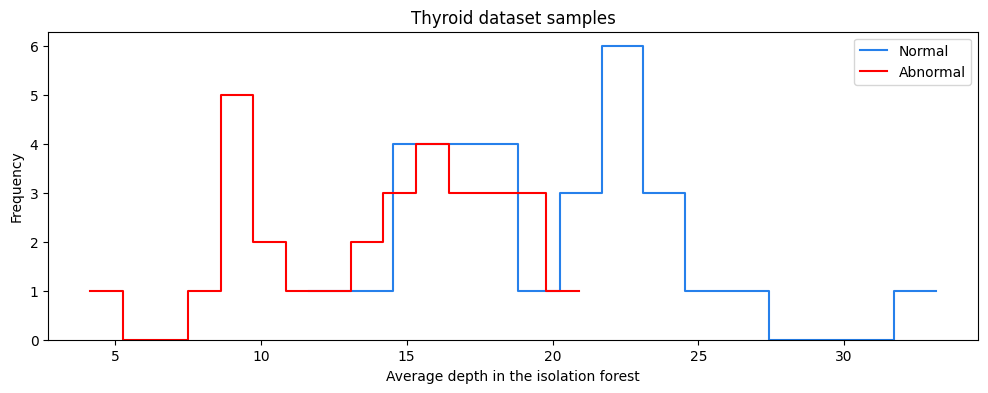

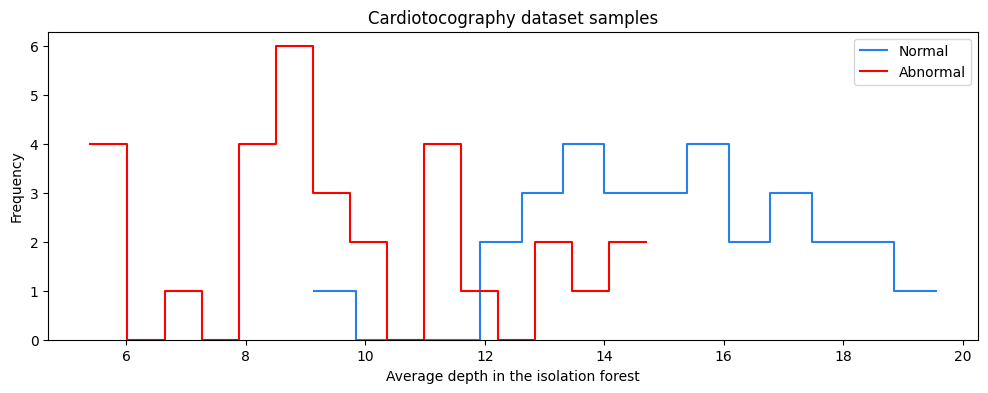

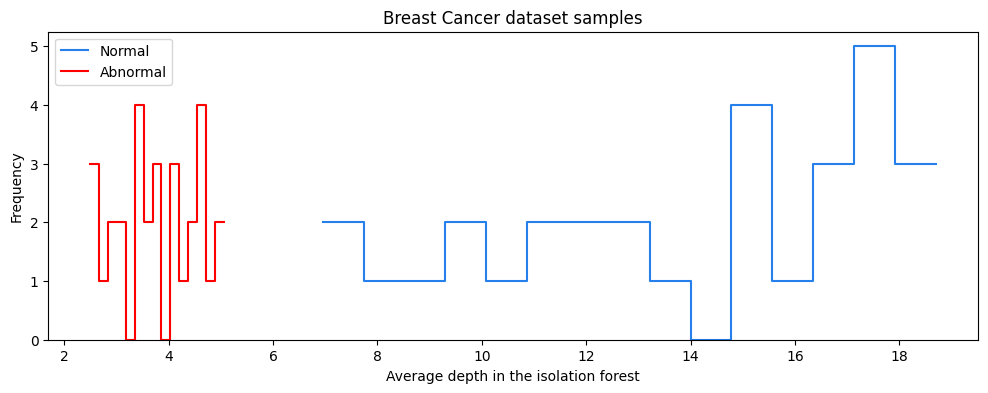

In [30]:
# LEAVE AS-IS

def plot_depth_histogram(normal_depths, abnormal_depths, dataset_name):
    plt.figure(figsize=(12,4))
    sns.histplot(normal_depths, label="Normal", bins=15, stat="count", element="step", fill=False, color="#2680EB")
    sns.histplot(abnormal_depths, label="Abnormal", bins=15, stat="count", element="step", fill=False, color="red")
    plt.title(f"{dataset_name} dataset samples")
    plt.xlabel("Average depth in the isolation forest")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

plot_depth_histogram(normal_depths_thyroid, abnormal_depths_thyroid, 'Thyroid')
plot_depth_histogram(normal_depths_cardio, abnormal_depths_cardio, 'Cardiotocography')
plot_depth_histogram(normal_depths_breastcancer, abnormal_depths_breastcancer, 'Breast Cancer')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What do you observe regarding the histograms of depths of normal and abnormal items in the three datasets? 

* These histogram again shows that the average depth of abnormal items are shallower than normal items.

In which of the datasets there is more overlap? In which one there is less overlap?

* Thyroid dataset has more overlap. Breast cancer dataset has less overlap.

## 4.2. Compute outlier scores and conclude <font color="#2680EB">[10%]</font>

In [31]:
# LEAVE THIS CODE AS-IS
# Source: https://stackoverflow.com/a/27683292/1235784

from numpy import euler_gamma
from scipy.special import digamma
def harmonic(s):
    return digamma(s + 1) + euler_gamma

In [32]:
# LEAVE THIS CODE AS-IS

def outlier_score_factory(df):
    n = len(df.index)
    c_n = 2.0 * harmonic(n - 1.0) - (2.0 * (n-1)/n)
    return lambda d: 2.0**(-d/c_n)

outlier_score_thyroid = outlier_score_factory(dfti)
outlier_score_cardio = outlier_score_factory(dfci)
outlier_score_breastcancer = outlier_score_factory(dfbi)

# Compute the scores for thyroid
normal_scores_thyroid = [outlier_score_thyroid(d) for d in normal_depths_thyroid]
abnormal_scores_thyroid = [outlier_score_thyroid(d) for d in abnormal_depths_thyroid]

# Compute the scores for cardio
normal_scores_cardio = [outlier_score_cardio(d) for d in normal_depths_cardio]
abnormal_scores_cardio = [outlier_score_cardio(d) for d in abnormal_depths_cardio]

# Compute the scores for breast cancer
normal_scores_breastcancer = [outlier_score_breastcancer(d) for d in normal_depths_breastcancer]
abnormal_scores_breastcancer = [outlier_score_breastcancer(d) for d in abnormal_depths_breastcancer]


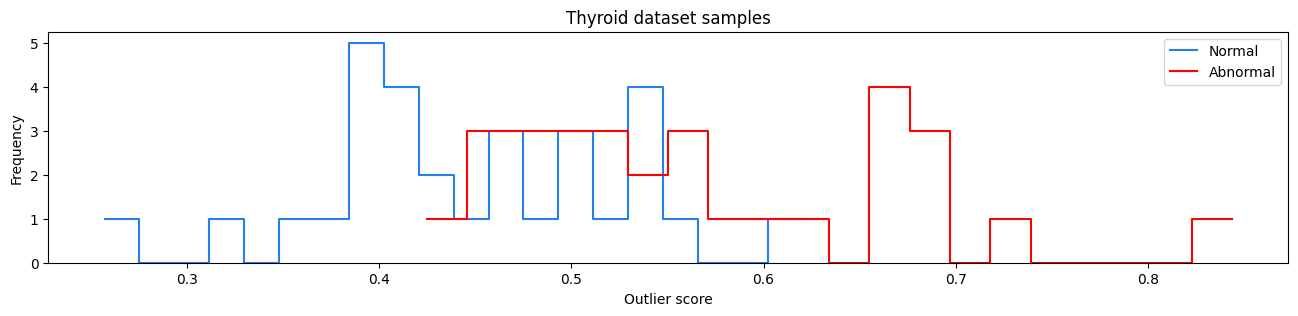

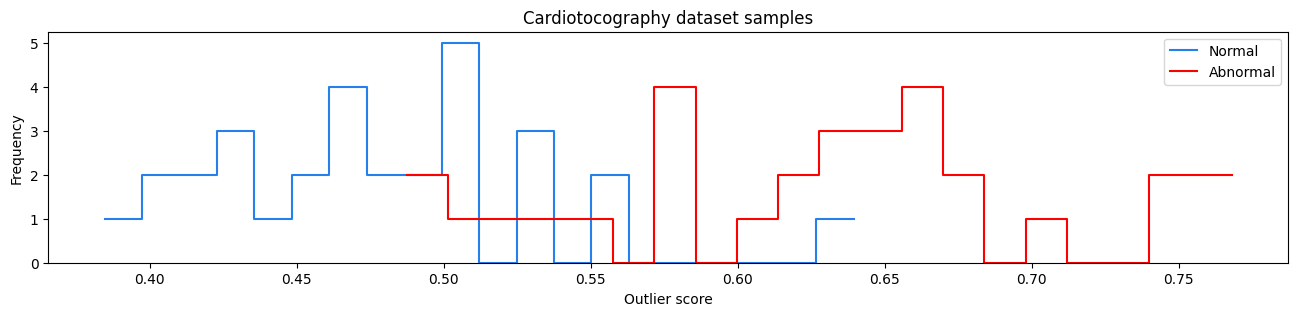

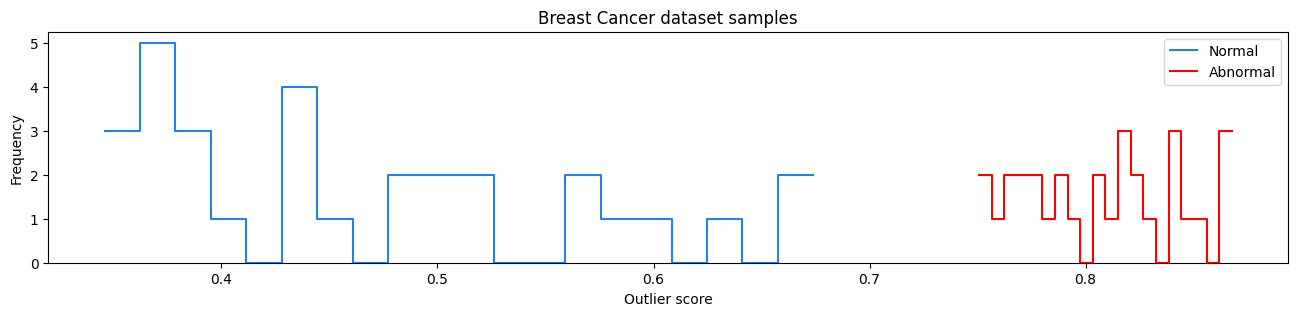

In [33]:
# LEAVE AS-IS

def plot_outlier_score_histogram(normal_scores, abnormal_scores, dataset_name):
    plt.figure(figsize=(16,3))
    sns.histplot(normal_scores, label="Normal", bins=20, stat="count", element="step", fill=False, color="#2680EB")
    sns.histplot(abnormal_scores, label="Abnormal", bins=20, stat="count", element="step", fill=False, color="red")
    plt.title(f"{dataset_name} dataset samples")
    plt.xlabel("Outlier score")
    plt.ylabel("Frequency")
    plt.legend()
    plt.show()

plot_outlier_score_histogram(normal_scores_thyroid, abnormal_scores_thyroid, 'Thyroid')
plot_outlier_score_histogram(normal_scores_cardio, abnormal_scores_cardio, 'Cardiotocography')
plot_outlier_score_histogram(normal_scores_breastcancer, abnormal_scores_breastcancer, 'Breast Cancer')

<font size="+1" color="#2680EB">**Answer the following questions.**</font>

**Answer:**

What do you observe regarding the histograms of outlier scores in the three datasets? 

* 1. abnormal data points usually have a higher outlier score. 2. Breast cancer abnormal points' outlier score has almost no overlaps with the outlier scores of normal datapoints.

How would you use it to **detect** outliers? 

* I would set a suitable threshold for each dataset. For example, 0.6 for Thyroid, 0.6 for cardiotocography and 0.7 for Breast Cancer, and data points with outlier score higher than the threshold would be consider outliers.


<font size="+2" color="#00A365">I hereby declare that I completed this practice myself, that my answers were not written by an AI-enabled code assistant, and that except for the code provided by the course instructors, all of my code, report, and figures were produced by myself.</font>